# Chapter 1: Data Processing
A) We'll perform an Exploratory Data Analysis (EDA) on the ECG Heartbeat Categorization Dataset to generate any initial insights into the data (e.g. the distribution of classes, missing data problems, statistical properties of the features, and any other relevant observations).

B) We'll apply data augmentation techniques to enhance the diversity of the dataset to (hopefully) produce a more robust final model.

In [1]:
%load_ext autoreload
%autoreload 2

### Required package imports

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import resample
import numpy as np

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report

from resnet_hearthealth_monitor.config import PROCESSED_DATA_DIR, RAW_DATA_DIR
from resnet_hearthealth_monitor.data_processing.preprocess import generate_cropped_dataset
from resnet_hearthealth_monitor.data_processing.augmentations import Augment, Gaussian_Noise, Baseline_Wander, Stretch, Amplify

2025-07-29 13:29:09.614 | INFO     | lightweight_resnet_heart_monitor.config:<module>:12 - PROJ_ROOT path is: /home/anthony/home/github/lightweight_resnet_heart_monitor


2025-07-29 13:29:09.678 | INFO     | lightweight_resnet_heart_monitor.config:<module>:41 - DEVICE is set to: cuda


/home/anthony/.virtualenvs/lightweight_resnet_heart_monitor/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# A) Exploratory Data Analysis (EDA) 

## Data head and shape

### Please first perform make data to generate raw data

In [3]:

# Define the file paths
train_path = '../data/raw/mitbih_train.csv'
test_path = '../data/raw/mitbih_test.csv'

# Read the CSV files into DataFrames
train_df = pd.read_csv(train_path, header=None)  # Use header=0 if your CSV has a header row
test_df = pd.read_csv(test_path, header=None)

# Display the first few rows of each DataFrame
print("Training Data:")
print(train_df.head())

print("\nTest Data:")
print(test_df.head())

train_df.shape, test_df.shape

Training Data:
        0         1         2         3         4         5         6    \
0  0.977941  0.926471  0.681373  0.245098  0.154412  0.191176  0.151961   
1  0.960114  0.863248  0.461538  0.196581  0.094017  0.125356  0.099715   
2  1.000000  0.659459  0.186486  0.070270  0.070270  0.059459  0.056757   
3  0.925414  0.665746  0.541436  0.276243  0.196133  0.077348  0.071823   
4  0.967136  1.000000  0.830986  0.586854  0.356808  0.248826  0.145540   

        7         8         9    ...  178  179  180  181  182  183  184  185  \
0  0.085784  0.058824  0.049020  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.088319  0.074074  0.082621  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.043243  0.054054  0.045946  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
3  0.060773  0.066298  0.058011  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
4  0.089202  0.117371  0.150235  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

   186  187  
0  0.0  0.0  
1  0.0  0.0  
2  0.0  0.0

((87554, 188), (21892, 188))

### Timeseries activity of shape 1x187 per sample, with 87.5k and 21.8k samples for train and test sets, respectively

## Target categories and their distribution

Class Distribution:
Class 0.0: 72471 samples (82.77%)
Class 1.0: 2223 samples (2.54%)
Class 2.0: 5788 samples (6.61%)
Class 3.0: 641 samples (0.73%)
Class 4.0: 6431 samples (7.35%)


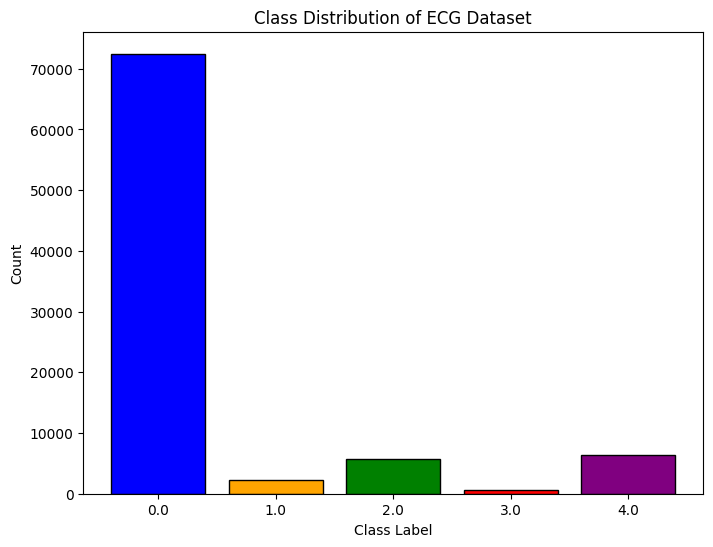

In [4]:
# Define the color mapping for each category (0-4)
color_mapping = {0: 'blue', 1: 'orange', 2: 'green', 3: 'red', 4: 'purple'}

# Assume train_df is your DataFrame and column 187 holds the class labels (0, 1, 2, 3, 4)
label_column = 187
labels = train_df.iloc[:, label_column]

# Calculate counts per class (ensuring classes appear in order 0-4)
counts = labels.value_counts().sort_index()

# Print class distribution statistics
total_samples = len(labels)
print("Class Distribution:")
for cls, count in counts.items():
    percentage = count / total_samples * 100
    print(f"Class {cls}: {count} samples ({percentage:.2f}%)")

# Plot the class distribution
plt.figure(figsize=(8, 6))
# Use our color mapping to set the color for each bar
bar_colors = [color_mapping.get(cls, 'grey') for cls in counts.index]
plt.bar(counts.index.astype(str), counts.values, color=bar_colors, edgecolor='black')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.title('Class Distribution of ECG Dataset')
plt.show()


### Target classes are highly imbalanced, with the large majority being healthy control beats

### We will use a weighted loss function during training to accommodate for this imbalance. If performance remains unacceptable for minority classes we may resort to oversampling/bootstrapping or undersampling of the majority class or both.

## Any missing data/Nans?

In [5]:
missing_per_column = train_df.isnull().sum()
print("Missing values per train_df column:")
print(missing_per_column)

# Check if there is any missing value in the entire DataFrame
if train_df.isnull().values.any():
    print("There are missing values in train_df.")
else:
    print("No missing values found in train_df.")


Missing values per train_df column:
0      0
1      0
2      0
3      0
4      0
      ..
183    0
184    0
185    0
186    0
187    0
Length: 188, dtype: int64
No missing values found in train_df.


In [6]:
missing_per_column = test_df.isnull().sum()
print("Missing values per test_df column:")
print(missing_per_column)

# Check if there is any missing value in the entire DataFrame
if test_df.isnull().values.any():
    print("There are missing values in test_df.")
else:
    print("No missing values found in test_df.")

Missing values per test_df column:
0      0
1      0
2      0
3      0
4      0
      ..
183    0
184    0
185    0
186    0
187    0
Length: 188, dtype: int64
No missing values found in test_df.


### No nans/missing data

# How do the timeseries averages look visually per class?

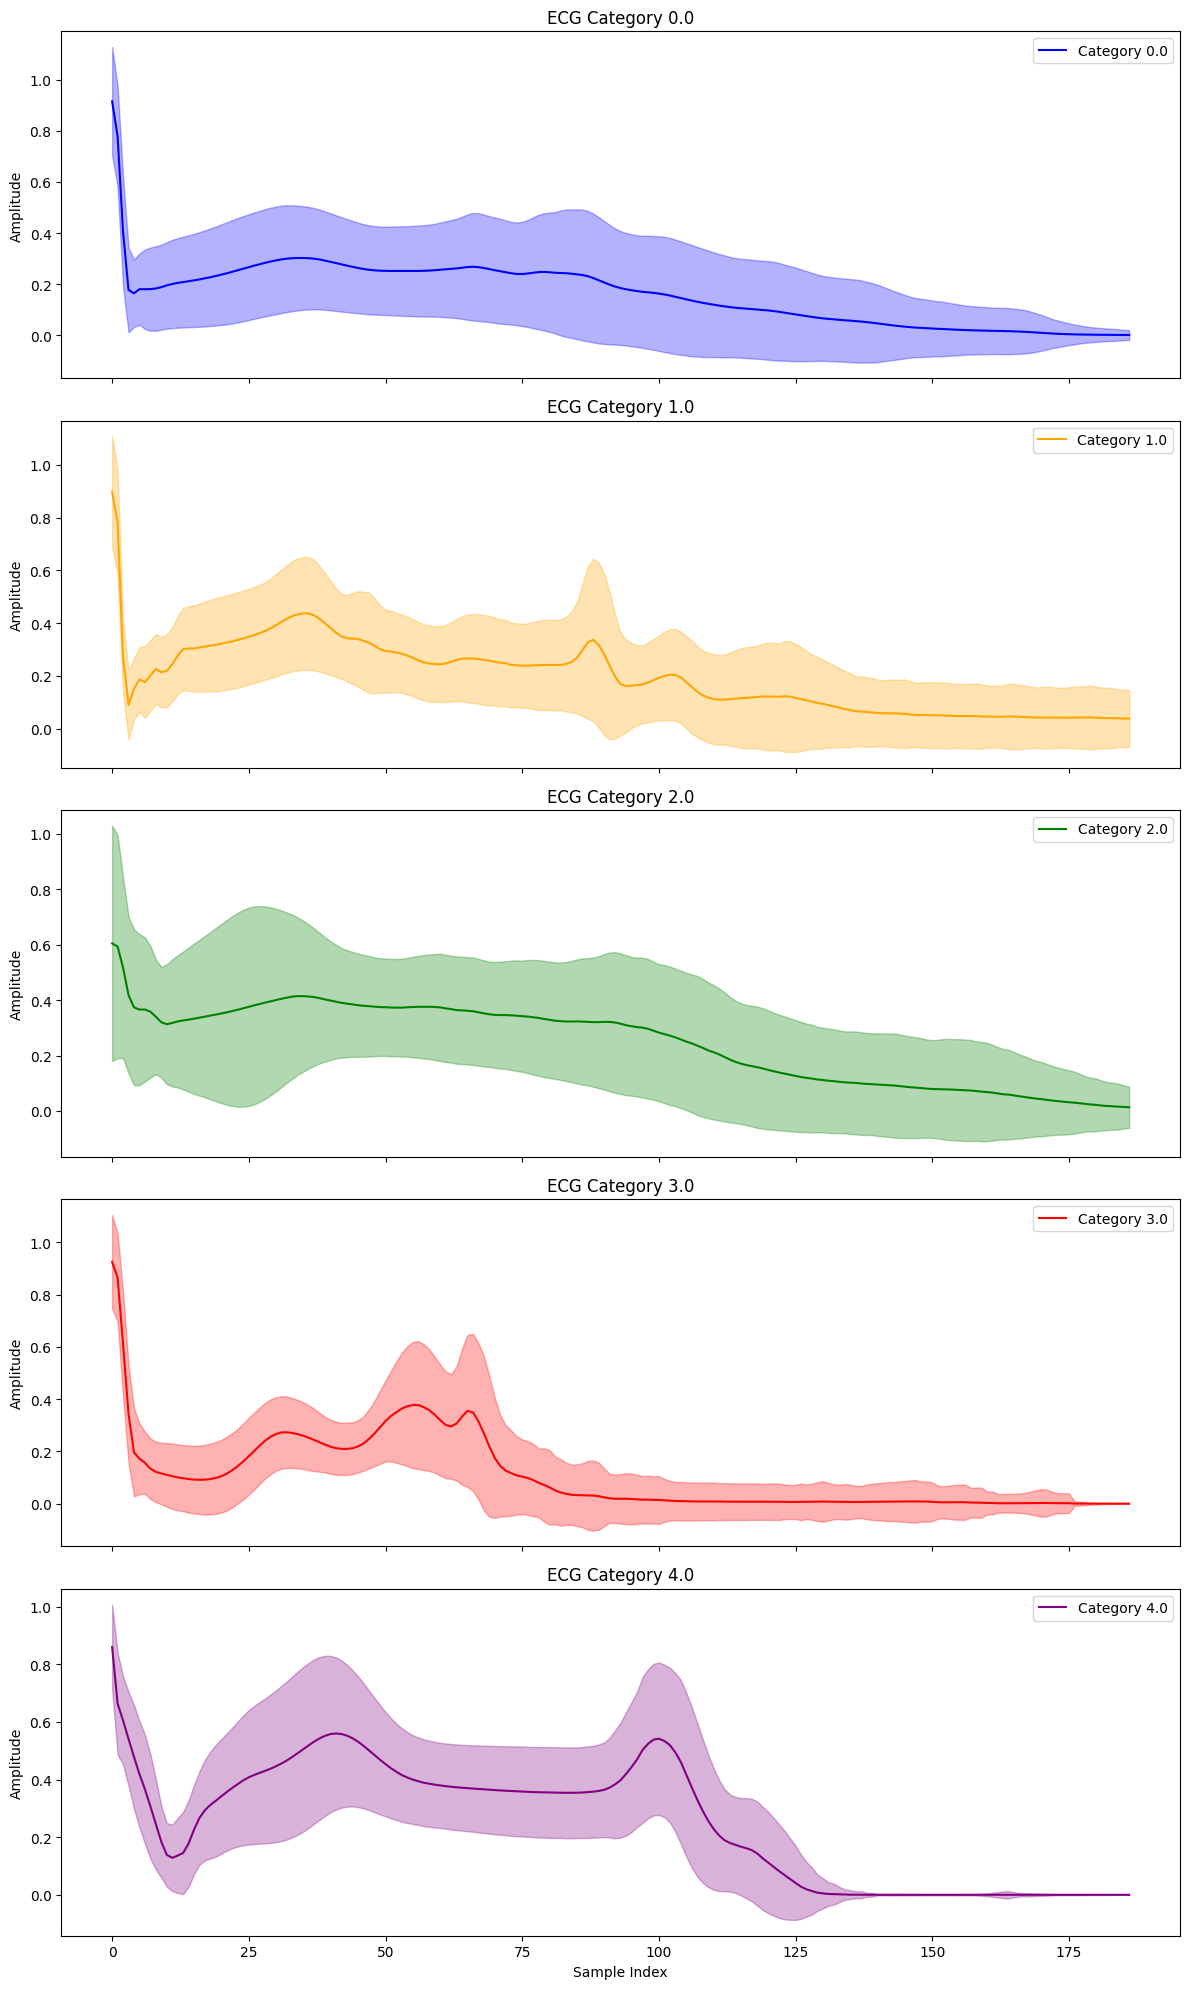

In [7]:
# Define signal columns and label column
signal_columns = list(range(187))  # Columns 0 to 186 are the ECG signal (187 points)
label_column = 187                # Column 187 holds the category label as an integer (0-4)

# Assuming train_df is your DataFrame loaded with the dataset
# Group the data by the integer label (category)
grouped = train_df.groupby(label_column)

# Create a subplot for each category
num_categories = len(grouped)
fig, axs = plt.subplots(num_categories, 1, figsize=(12, 4 * num_categories), sharex=True)

# If there's only one category, wrap it in a list for consistency
if num_categories == 1:
    axs = [axs]

# Iterate through each category and plot the mean ± std
for ax, (category, group) in zip(axs, grouped):
    # Get the assigned color from our color mapping
    color = color_mapping.get(category, 'blue')
    
    # Get the ECG signals as a numpy array
    signals = group[signal_columns].to_numpy()
    mean_signal = np.mean(signals, axis=0)
    std_signal = np.std(signals, axis=0)
    x = np.arange(187)  # x-axis: sample indices from 0 to 186
    
    # Plot the mean signal and standard deviation using the assigned color
    ax.plot(x, mean_signal, label=f'Category {category}', color=color)
    ax.fill_between(x, mean_signal - std_signal, mean_signal + std_signal, color=color, alpha=0.3)
    
    ax.set_title(f'ECG Category {category}')
    ax.set_ylabel('Amplitude')
    ax.legend()

# Set common x-label and adjust layout
axs[-1].set_xlabel('Sample Index')
plt.tight_layout()
plt.show()


### Timeseries per class look learnable, relatively unique and without too much noise

# How about outliers? Are there many? 

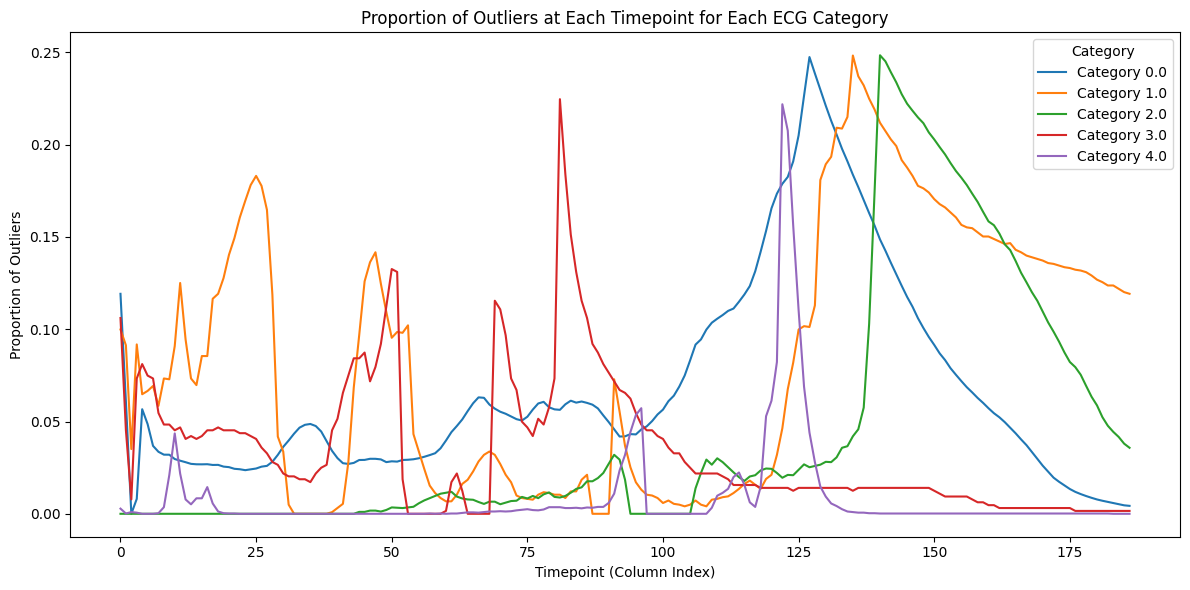

In [8]:
# Function to count outliers in a Series using the IQR method
def count_outliers(series, factor=1.5):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return outliers.shape[0]

# Define the signal columns and label column
signal_columns = list(range(187))  # Columns 0 to 186
label_column = 187                # Column 187 holds the category label

# Dictionary to hold outlier proportions for each category
# Key: category, Value: list of proportions per timepoint
outlier_proportions = {}

# Group the data by category and compute the proportion of outliers per timepoint
for category, group in train_df.groupby(label_column):
    total_samples = group.shape[0]
    # Calculate proportion of outliers for each timepoint
    proportions = [count_outliers(group[col]) / total_samples for col in signal_columns]
    outlier_proportions[category] = proportions

# Plot the outlier proportions for each category
plt.figure(figsize=(12, 6))
for category, proportions in outlier_proportions.items():
    plt.plot(range(187), proportions, label=f'Category {category}')

plt.xlabel('Timepoint (Column Index)')
plt.ylabel('Proportion of Outliers')
plt.title('Proportion of Outliers at Each Timepoint for Each ECG Category')
plt.legend(title='Category')
plt.tight_layout()
plt.show()


### Interesting that after timepoint ~125 most signals have many outliers, why?

### Statistical characteristics of the timeseries at each point-in-time

In [9]:
descriptives = train_df.describe().T
print(descriptives)

       count      mean       std  min       25%       50%       75%  max
0    87554.0  0.890360  0.240909  0.0  0.921922  0.991342  1.000000  1.0
1    87554.0  0.758160  0.221813  0.0  0.682486  0.826013  0.910506  1.0
2    87554.0  0.423972  0.227305  0.0  0.250969  0.429472  0.578767  1.0
3    87554.0  0.219104  0.206878  0.0  0.048458  0.166000  0.341727  1.0
4    87554.0  0.201127  0.177058  0.0  0.082329  0.147878  0.258993  1.0
..       ...       ...       ...  ...       ...       ...       ...  ...
183  87554.0  0.003471  0.036255  0.0  0.000000  0.000000  0.000000  1.0
184  87554.0  0.003221  0.034789  0.0  0.000000  0.000000  0.000000  1.0
185  87554.0  0.002945  0.032865  0.0  0.000000  0.000000  0.000000  1.0
186  87554.0  0.002807  0.031924  0.0  0.000000  0.000000  0.000000  1.0
187  87554.0  0.473376  1.143184  0.0  0.000000  0.000000  0.000000  4.0

[188 rows x 8 columns]


In [10]:
print(descriptives.iloc[100:150,:])

       count      mean       std  min  25%       50%       75%  max
100  87554.0  0.198477  0.248718  0.0  0.0  0.098669  0.313152  1.0
101  87554.0  0.194976  0.249405  0.0  0.0  0.091543  0.309823  1.0
102  87554.0  0.190171  0.248523  0.0  0.0  0.083851  0.305542  1.0
103  87554.0  0.183723  0.246100  0.0  0.0  0.075000  0.298276  1.0
104  87554.0  0.176382  0.242779  0.0  0.0  0.065026  0.289572  1.0
105  87554.0  0.168045  0.237951  0.0  0.0  0.052632  0.278785  1.0
106  87554.0  0.159942  0.233138  0.0  0.0  0.037931  0.264846  1.0
107  87554.0  0.152076  0.227074  0.0  0.0  0.017223  0.250000  1.0
108  87554.0  0.144858  0.221258  0.0  0.0  0.000000  0.235024  1.0
109  87554.0  0.138517  0.215383  0.0  0.0  0.000000  0.220745  1.0
110  87554.0  0.132733  0.209885  0.0  0.0  0.000000  0.208317  1.0
111  87554.0  0.127601  0.204928  0.0  0.0  0.000000  0.195577  1.0
112  87554.0  0.123290  0.201116  0.0  0.0  0.000000  0.186000  1.0
113  87554.0  0.119552  0.197333  0.0  0.0  0.00

In [11]:
print(descriptives.iloc[150:,:])

       count      mean       std  min  25%  50%  75%  max
150  87554.0  0.028531  0.112686  0.0  0.0  0.0  0.0  1.0
151  87554.0  0.027573  0.111103  0.0  0.0  0.0  0.0  1.0
152  87554.0  0.026875  0.110513  0.0  0.0  0.0  0.0  1.0
153  87554.0  0.025771  0.108566  0.0  0.0  0.0  0.0  1.0
154  87554.0  0.024823  0.106493  0.0  0.0  0.0  0.0  1.0
155  87554.0  0.023932  0.104591  0.0  0.0  0.0  0.0  1.0
156  87554.0  0.023060  0.102658  0.0  0.0  0.0  0.0  1.0
157  87554.0  0.022458  0.101395  0.0  0.0  0.0  0.0  1.0
158  87554.0  0.021809  0.100201  0.0  0.0  0.0  0.0  1.0
159  87554.0  0.021245  0.099386  0.0  0.0  0.0  0.0  1.0
160  87554.0  0.020623  0.098327  0.0  0.0  0.0  0.0  1.0
161  87554.0  0.020026  0.096635  0.0  0.0  0.0  0.0  1.0
162  87554.0  0.019534  0.095729  0.0  0.0  0.0  0.0  1.0
163  87554.0  0.019053  0.095368  0.0  0.0  0.0  0.0  1.0
164  87554.0  0.018592  0.095055  0.0  0.0  0.0  0.0  1.0
165  87554.0  0.017664  0.092902  0.0  0.0  0.0  0.0  1.0
166  87554.0  

### From timepoint 125 onwards, the signal for all samples is largely 0, as evidenced by even the 75th percentile being 0. There could be some value to cropping the data to 125 points (may enhance model performance and/or reduce computational costs of model).

## Cropping the data, removing samples past time-point 125

In [12]:
train_input_path: Path = RAW_DATA_DIR / "mitbih_train.csv"
train_output_path: Path = PROCESSED_DATA_DIR / "mitbih_train_cropped.csv"
test_input_path: Path = RAW_DATA_DIR / "mitbih_test.csv"
test_output_path: Path = PROCESSED_DATA_DIR / "mitbih_test_cropped.csv"

train_df_cropped = generate_cropped_dataset(train_input_path, train_output_path, crop_position=125)
test_df_cropped = generate_cropped_dataset(test_input_path, test_output_path, crop_position=125)

2025-07-29 13:30:43.482 | INFO     | lightweight_resnet_heart_monitor.data_processing.preprocess:generate_cropped_dataset:42 - /home/anthony/home/github/lightweight_resnet_heart_monitor/data/processed/mitbih_train_cropped.csv already exists, not overwriting.
2025-07-29 13:30:43.868 | INFO     | lightweight_resnet_heart_monitor.data_processing.preprocess:generate_cropped_dataset:42 - /home/anthony/home/github/lightweight_resnet_heart_monitor/data/processed/mitbih_test_cropped.csv already exists, not overwriting.


### There remain some outliers, perhaps worth clipping on-line during PyTorch training but we will not make any modifications here so as not to introduce leakage in the cross-validated performance estimates we will generate later during hyperparameter tuning

## What about extreme outliers (+/- 3 IQR)?

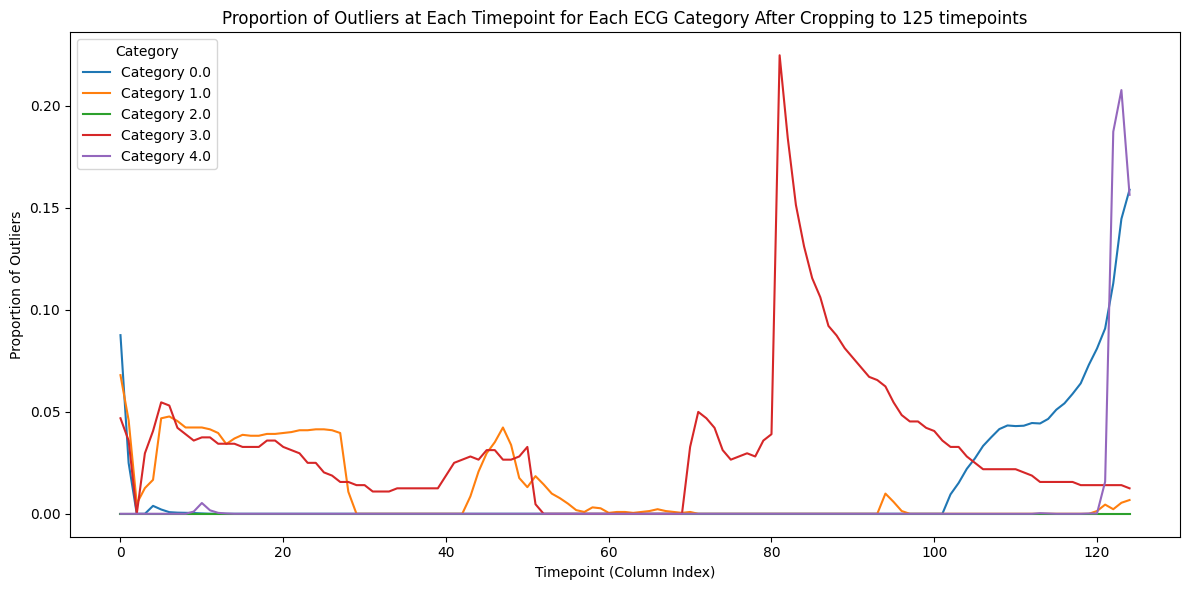

In [13]:
signal_columns = list(range(125))  # Columns 0 to 125
label_column = 187              # Column "187" still holds the category label

outlier_proportions = {}

# Group the data by category and compute the proportion of outliers per timepoint
for category, group in train_df_cropped.groupby(label_column):
    total_samples = group.shape[0]
    # Calculate proportion of outliers for each timepoint
    proportions = [count_outliers(group[col], factor=3) / total_samples for col in signal_columns]
    outlier_proportions[category] = proportions

# Plot the outlier proportions for each category
plt.figure(figsize=(12, 6))
for category, proportions in outlier_proportions.items():
    plt.plot(range(125), proportions, label=f'Category {category}')

plt.xlabel('Timepoint (Column Index)')
plt.ylabel('Proportion of Outliers')
plt.title('Proportion of Outliers at Each Timepoint for Each ECG Category After Cropping to 125 timepoints')
plt.legend(title='Category')
plt.tight_layout()
plt.show()

### Some exist, particularly with category 3, what is going on with category 3 timepoints 80-90?

In [14]:
for category, group in train_df_cropped.groupby(label_column):
    if category == 3:
        print(f"Category {category}:")
        print(group.describe().T.iloc[75:125, :])
        print("\n")


Category 3.0:
     count      mean       std  min  25%       50%       75%       max
75   641.0  0.103091  0.142547  0.0  0.0  0.086207  0.135286  1.000000
76   641.0  0.098479  0.141821  0.0  0.0  0.079942  0.129679  1.000000
77   641.0  0.090377  0.138590  0.0  0.0  0.067919  0.120061  0.982249
78   641.0  0.079913  0.131585  0.0  0.0  0.000000  0.116492  0.873085
79   641.0  0.071628  0.140179  0.0  0.0  0.000000  0.106178  0.954048
80   641.0  0.062405  0.142940  0.0  0.0  0.000000  0.088798  1.000000
81   641.0  0.051045  0.129738  0.0  0.0  0.000000  0.000000  0.940767
82   641.0  0.042872  0.127538  0.0  0.0  0.000000  0.000000  1.000000
83   641.0  0.038026  0.119542  0.0  0.0  0.000000  0.000000  0.960366
84   641.0  0.034208  0.115267  0.0  0.0  0.000000  0.000000  0.823328
85   641.0  0.032758  0.118022  0.0  0.0  0.000000  0.000000  0.879931
86   641.0  0.032312  0.122457  0.0  0.0  0.000000  0.000000  0.970790
87   641.0  0.031800  0.131885  0.0  0.0  0.000000  0.000000  1

### Okay it's just flat/0 signal by timepoint ~80 for this group of signals, possibly return to this later

# B) Data Augmentations

### Four Data augmentations will be used: Baseline wander, gaussian noise, amplify, and time scaling (stretch/shrink)
- Augmentations will be randomly selected (50% chance for each augmentation of being on for any given sample)

### Justifications:
- Baseline Wander: Simulates slow, low-frequency shifts in the signal baseline due to electrode motion or respiration, helping the model handle real-world drift.
- Gaussian Noise: Mimics sensor or measurement noise to improve model robustness against minor signal fluctuations.
- Amplifcation: Varies the signal amplitude to simulate differences in electrode placement or patient variability, encouraging scale invariance.
- Stretch/Shrink: Alters the time dimension to emulate variations in heart rate and signal timing, promoting temporal flexibility in the model.

### Sanity check: Let's briefly visualize their effects applied to some samples

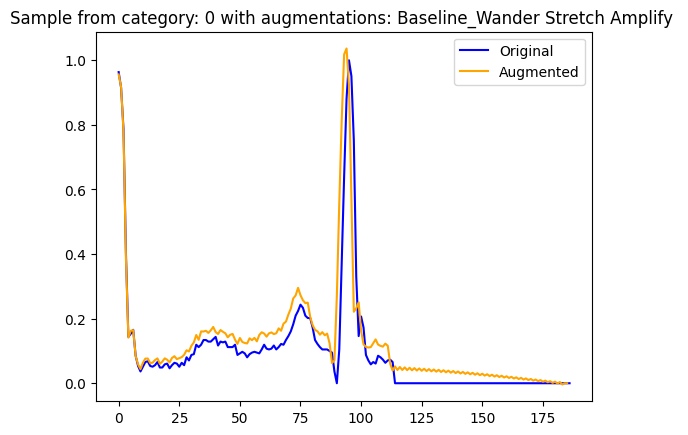

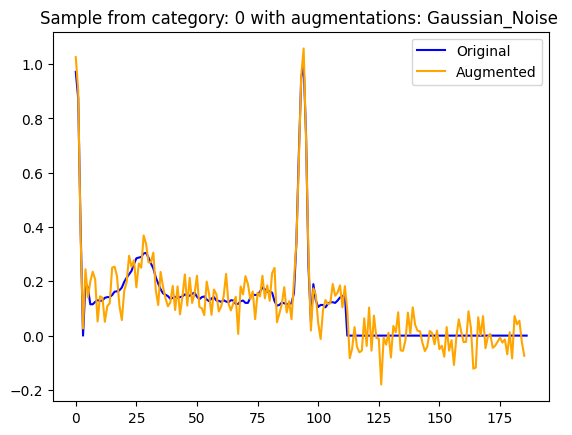

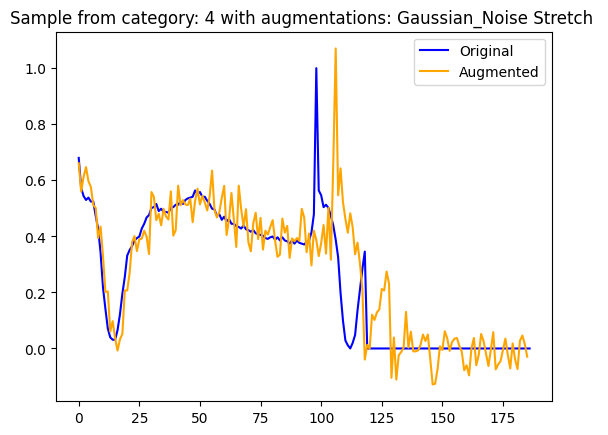

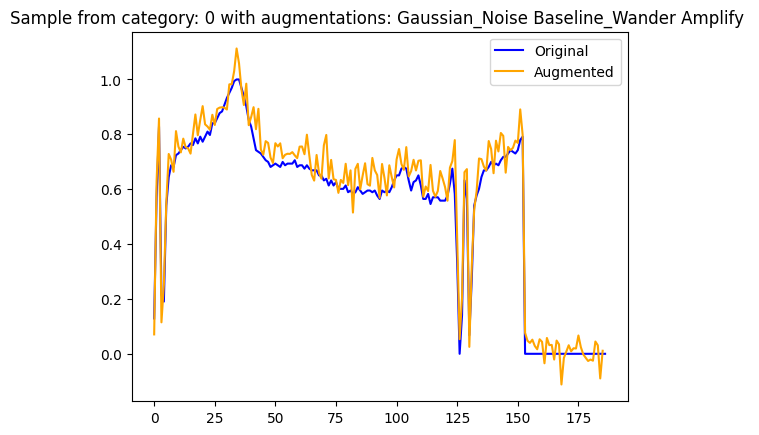

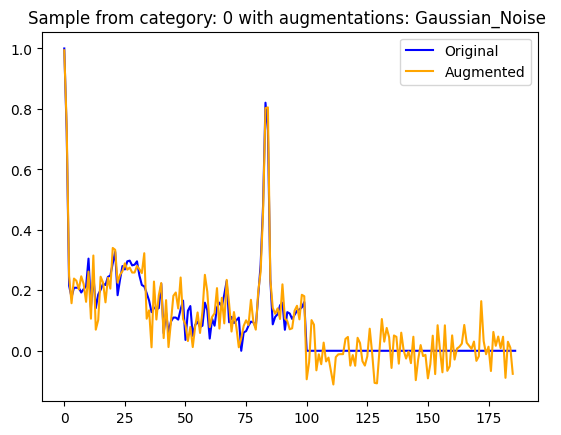

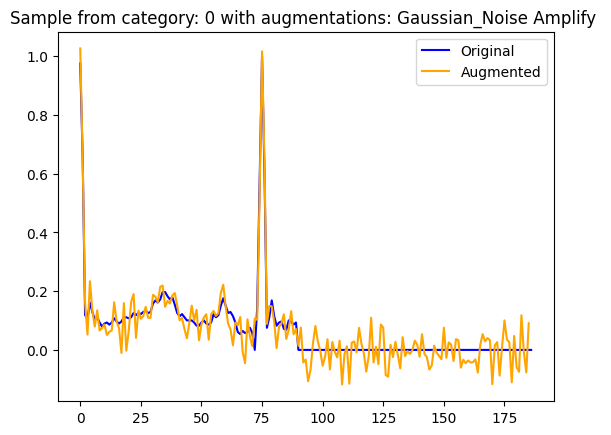

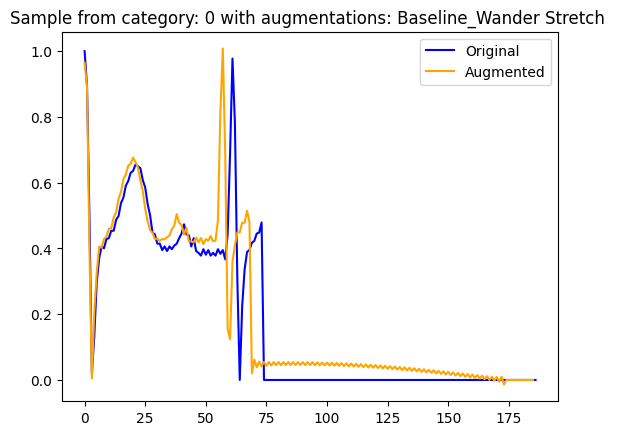

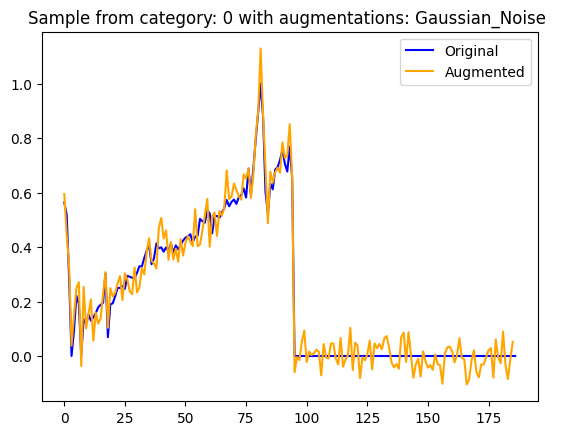

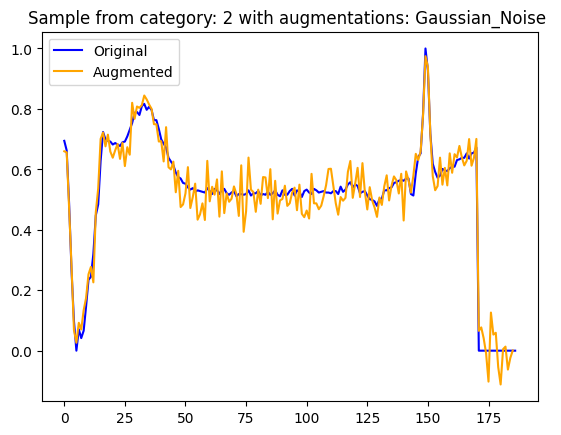

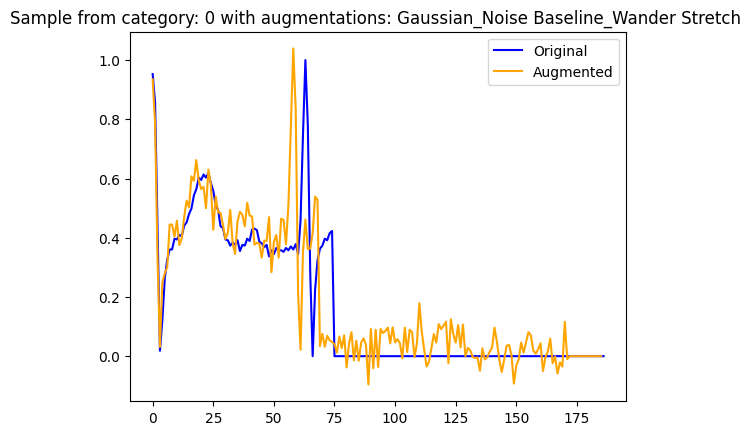

In [16]:
augment = Augment([Gaussian_Noise(), Baseline_Wander(), Stretch(), Amplify()], True)
for i in range(10):
    plt.figure()
    sample = train_df.sample(1).values.flatten()
    y = sample[-1]
    plt.plot(sample[:-1], label="Original", color="blue")
    
    augmented, augmentations_performed = augment(sample[:-1])
    plt.plot(augmented[:-1], label="Augmented", color="orange")
    
    title = plt.title(f'Sample from category: {str(y.astype(int))}' + ' with augmentations: ' + (augmentations_performed if augmentations_performed != '' else 'No Augmentations'))
    plt.legend()
    plt.show()

# Let's now move to chapter 2 and see how some Pytorch modeling performs